# **PHYS 249: Assignment 2 - The Invisible Patient: Reconstructing an Image**

##### $\text{\it{Basil Droulias, Owen Dumancic}}$

### $\text{Part A}$

The variables $x_1,\dotsc,x_4$ represent each pixel of the object's linear attenuation coefficient, how much intensity an X-ray loses by passing through the corresponding pixel. We can deduce both that each $x_i$ must be nonnegative, and the effect of a larger $x_i$ on $I$, by analyzing the mathematical relationships provided in the imaging model; examining them, we find

$$ I = I_0e^{-(\ell \cdot \boldsymbol{x})} = \frac{I_0}{e^{\ell \cdot \boldsymbol{x}}}$$

Firstly, suppose we are have the path-length vector $\ell = (1,0,0,0)$ and $x_1 < 0$; then $\ell \cdot \boldsymbol{x} < 0$, and our expression for $I$ says $I > I_0$, meaning the X-ray gained intensity from the interaction with the material - something not physically possible in this case. Secondly, suppose we have the same $\ell$ but with $x_1 > 0$; as $x_1$ grows, the denominator grows, and so the measured intensity decreases. For the material, this means it absorbs X-rays more strongly, such as bone in comparison to soft tissue.

The reason we can represent an X-ray measurement as a dot product results from the physical meanings of $\ell$ and $\boldsymbol{x}$. We have that:
- $\ell_j$ is the beam's path length through pixel $j$.
- $x_j$ is the attenuation per unit length.
- and $\ell_j·x_j$ is that pixel's contribution.

The logarithmic attenuation $p$ is the sum of each contributing pixel's attenuation, but only pixels the ray passes through will weaken the ray. Since $\ell_i$ tells us if the ray passes through the pixel corresponding to $x_i$, calculating $\mathbf{\ell} \cdot \boldsymbol{x}$ sums only the attenuations of pixels the ray crosses.
For example, with a path length vector $\mathbf{\ell} = (0, 1, 0, 1)$, the dot product $\mathbf{\ell} \cdot \boldsymbol{x}$ is 

$$
    \begin{align*}
        p &= 0(x_1) + 1(x_2) + 0(x_3) + 1(x_4)
        \\
        &= x_2 + x_4
    \end{align*}
$$

and we can see only $x_2$ and $x_4$ contribute because the ray only crosses these pixels (zero entries in the path length vector mean the ray does not cross those pixels).

**What does this mean?** We found that the ray $\boldsymbol{\ell} = (0, 1, 0, 1)$ only measures $p = x_2 + x_4$, meaning that each measurement is the total attenuation of only the pixels the ray crosses, because the zero entries of $\boldsymbol{\ell}$ cancel the other pixels out of the dot product.


### $\text{Part B}$

We must take the dot product of each path-length vector with the pixel vector. 


**Measurement 1:**
$$
(1,1,0,0)\cdot
\begin{pmatrix}
x_1\
x_2\
x_3\
x_4
\end{pmatrix}=5
\\[0.5em]
\boxed{x_1+x_2=5}
$$
**Measurement 2:**
$$
(0,0,1,1)\cdot
\begin{pmatrix}
x_1\
x_2\
x_3\
x_4
\end{pmatrix}=9
\\[0.5em]
\boxed{x_3+x_4=9}
$$
**Measurement 3:**
$$
(1,0,1,0)\cdot
\begin{pmatrix}
x_1\
x_2\
x_3\
x_4
\end{pmatrix}=6
\\[0.5em]
\boxed{x_1+x_3=6}
$$
**Measurement 4:**
$$
(1,0,0,1)\cdot
\begin{pmatrix}
x_1\
x_2\
x_3\
x_4
\end{pmatrix}=7
\\[0.5em]
\boxed{x_1+x_4=7}
$$
For measurement 1, the path-length vector is $(1,1,0,0)$. This means that the X-ray passes through the two top pixels but not the bottom two. The attenuation is the result of the dot product between the path-length vector and the pixel vector, which equals 5.

The vector projection of $\boldsymbol{z} = (1, 4, 2, 5)^T$ onto $\boldsymbol{\ell}_1 = (1, 1, 0, 0)^T$ is

$$\text{proj}_{\boldsymbol{\ell}_1}\boldsymbol{z} = \left(\frac{\boldsymbol{z}\cdot\boldsymbol{\ell}_1}{\boldsymbol{\ell}_1\cdot\boldsymbol{\ell}_1}\right)\boldsymbol{\ell}_1$$

Calculating each dot product, we find

$$
\begin{aligned}
\boldsymbol{z}\cdot\boldsymbol{\ell}_1 &= 1(1) + 4(1) + 2(0) + 5(0) = 5 \\
\boldsymbol{\ell}_1\cdot\boldsymbol{\ell}_1 &= 1^2 + 1^2 + 0^2 + 0^2 = 2
\end{aligned}
$$

and so

$$\text{proj}_{\boldsymbol{\ell}_1}\boldsymbol{z} = \frac{5}{2}(1, 1, 0, 0)^T = \boxed{\left(\tfrac{5}{2},\ \tfrac{5}{2},\ 0,\ 0\right)^T}$$

The projection depends on $\boldsymbol{z}$ only through the single number $\boldsymbol{z}\cdot\boldsymbol{\ell}_1 = z_1 + z_2 = 5$, so any part of $\boldsymbol{z}$ perpendicular to $\boldsymbol{\ell}_1$ (the bottom pixels $z_3 = 2$ and $z_4 = 5$, and how the total of 5 is split between $z_1$ and $z_2$) is lost.

This measurement alone cannot determine all four pixel values; it yields a single equation, $x_1 + x_2 = 5$, in four unknowns, which leaves three free variables. We can see this with our own numbers: $\boldsymbol{z} = (1, 4, 2, 5)^T$ gives $\boldsymbol{z}\cdot\boldsymbol{\ell}_1 = 5$, which matches the measured $p_1 = 5$. Similarly, the image we reconstruct in Part C, $\boldsymbol{x} = (2, 3, 4, 5)^T$, also gives $\boldsymbol{x}\cdot\boldsymbol{\ell}_1 = 2 + 3 = 5$ and has the same projection $\left(\tfrac{5}{2}, \tfrac{5}{2}, 0, 0\right)^T$, even though the two images are different.

**What does this mean?** We found that $\boldsymbol{z} = (1, 4, 2, 5)^T$ and our reconstructed image $(2, 3, 4, 5)^T$ both give $p_1 = 5$ and the same projection $\left(\tfrac{5}{2}, \tfrac{5}{2}, 0, 0\right)^T$, meaning that one measurement cannot tell two different images apart, because it only records the total attenuation along the top row.


### $\text{Part C}$

From the measurement equations in part B, we can form the system's coefficient matrix $A$ and measurement vector $\boldsymbol{b}$

$$
A = 
\begin{bmatrix}
    1 & 1 & 0 & 0 \\
    0 & 0 & 1 & 1 \\
    1 & 0 & 1 & 0 \\
    1 & 0 & 0 & 1
\end{bmatrix},  \quad \quad
\boldsymbol{b} =
\begin{bmatrix}
    5 \\
    9 \\
    6 \\
    7
\end{bmatrix}
$$

with $\text{dim}(A) = 4 \times 4$, and $\text{dim}(\boldsymbol{b}) = 4 \times 1$

Now that we have the corresponding coefficient matrix and measurement vector, we can form the system's augmented matrix vector $[\ A\ |\ \mathbf{b}\ ]$:

$$
\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 1 & 0 & 1 & 0 \\
\ 1 & 0 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
9\ \\
6\ \\
7\ \\
\end{matrix}
\right]
$$

which we can convert to RREF as follows:

$$
\begin{aligned}
&\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 1 & 0 & 1 & 0 \\
\ 1 & 0 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
9\ \\
6\ \\
7\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
{} \\
R_3 - R_1 \\
R_4 - R_1 \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & -1 & 1 & 0 \\
\ 0 & -1 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
9\ \\
1\ \\
2\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
R_2 \updownarrow R_3 \\
{} \\
{} \\
\end{array}
\\[1.25em]
&\rule{30em}{0.00000000000000001pt}
\\[0.5em]
\sim
&\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & -1 & 1 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & -1 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
1\ \\
9\ \\
2\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
(-1)R_2 \\
{} \\
{} \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 1 & -1 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & -1 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
-1\ \\
9\ \\
2\ \\
\end{matrix}
\right]
\begin{array}{l}
R_1 - R_2 \\
{} \\
{} \\
R_4 + R_2 \\
\end{array}
\\[1.25em]
&\rule{30em}{0.00000000000000001pt}
\\[0.5em]
\sim
&\left[
\begin{matrix}
\ 1 & 0 & 1 & 0 \\
\ 0 & 1 & -1 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & 0 & -1 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
6\ \\
-1\ \\
9\ \\
1\ \\
\end{matrix}
\right]
\begin{array}{l}
R_1 - R_3 \\
R_2 + R_3 \\
{} \\
R_4 + R_3 \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 0 & 0 & -1 \\
\ 0 & 1 & 0 & 1 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & 0 & 0 & 2 \\
\end{matrix} \
\middle| \
\begin{matrix}
-3\ \\
8\ \\
9\ \\
10\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
{} \\
{} \\
(1/2)R_4 \\
\end{array}
\\[1.25em]
&\rule{30em}{0.0000000000000000001pt}
\\[0.5em]
\sim
&\left[
\begin{matrix}
\ 1 & 0 & 0 & -1 \\
\ 0 & 1 & 0 & 1 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & 0 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
-3\ \\
8\ \\
9\ \\
5\ \\
\end{matrix}
\right]
\begin{array}{l}
R_1 + R_4 \\
R_2 - R_4 \\
R_3 - R_4 \\
{} \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 0 & 0 & 0 \\
\ 0 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 0 \\
\ 0 & 0 & 0 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
2\ \\
3\ \\
4\ \\
5\ \\
\end{matrix}
\right]
\quad \text{RREF}
\end{aligned}
$$

From the RREF form, we are left with the solution set $(x_1, x_2, x_3, x_4)^T = (2,\ 3,\ 4,\ 5)^T$, which corresponds to the reconstructed image 

$$
X = 
\begin{bmatrix}
    2 & 3 \\
    4 & 5
\end{bmatrix}
$$

We know these values are uniquely determined because every variable of the RREF matrix has a pivot column and there are no contradictions.

**What does this mean?** We found the unique image $X = \begin{bmatrix} 2 & 3 \\ 4 & 5 \end{bmatrix}$, meaning that our four measurements are enough to recover every pixel exactly, because the RREF of $[A \mid \boldsymbol{b}]$ has a pivot in all 4 columns.

### $\text{Part D}$

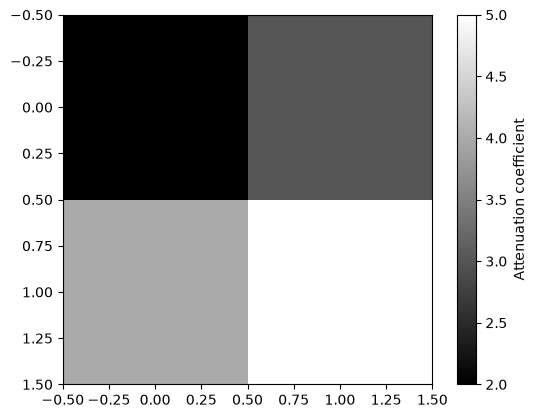

In [6]:
import matplotlib.pyplot as plt
import numpy as np

A = np.array([[1, 1, 0, 0], [0, 0, 1, 1], [1, 0, 1, 0], [1, 0, 0, 1]]) # initialize coefficient matrix A
b = np.array([[5], [9], [6], [7]]) # initialize measurement vector b

x = np.linalg.solve(A, b).reshape(2, 2) # find solution vector x and reshape into a 2x2 matrix [x1 x2 / x3 x4]

# display the 2x2 solution matrix for x
plt.imshow(x, cmap="gray", interpolation="nearest")
plt.colorbar(label="Attenuation coefficient")
plt.show()

We observe that pixel 4 has the greatest attenuation, meaning that physically, it reduces X-ray intensity the **most** of all 4 pixels.

In [12]:
# verify Ax = b using np.allclose and print the result
print(np.allclose(A @ x.reshape(4, 1), b))
print(A @ x.reshape(4, 1))

True
[[5.]
 [9.]
 [6.]
 [7.]]


`np.allclose` returning true establishes that our solution set $x$ is mathematically consistent with our idealized system of linear equations. `np.allclose` does not, however, establish that our solution set or model is physically accurate for a real object; it only determines whether our idealized model is consistent. 

**What does this mean?** We found that Python gives the same image as our hand calculation, with $x_4 = 5$ as the most attenuating pixel, and that $A\boldsymbol{x}$ reproduces $\boldsymbol{b} = (5, 9, 6, 7)^T$ exactly, meaning that our image fits every measurement in our idealized model but not necessarily a real patient, because real measurements contain noise.

### $\text{Part E}$

After removing measurement 4, the resulting augmented matrix is:

$$
\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 1 & 0 & 1 & 0 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
9\ \\
6\ \\
\end{matrix}
\right]
$$

and it's RREF form can be determined as follows:

$$
\begin{aligned}
&\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 1 & 0 & 1 & 0 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
9\ \\
6\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
{} \\
R_3 - R_1 \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 0 & 1 & 1 \\
\ 0 & -1 & 1 & 0 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
9\ \\
1\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
R_2 \updownarrow R_3 \\
{} \\
\end{array}
\\[1.25em]
&\rule{30em}{0.00000000000000001pt}
\\[0.5em]
\sim
&\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & -1 & 1 & 0 \\
\ 0 & 0 & 1 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
1\ \\
9\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
(-1)R_2 \\
{} \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 1 & 0 & 0 \\
\ 0 & 1 & -1 & 0 \\
\ 0 & 0 & 1 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
5\ \\
-1\ \\
9\ \\
\end{matrix}
\right]
\begin{array}{l}
R_1 - R_2 \\
{} \\
{} \\
\end{array}
\\[1.25em]
&\rule{30em}{0.00000000000000001pt}
\\[0.5em]
\sim
&\left[
\begin{matrix}
\ 1 & 0 & 1 & 0 \\
\ 0 & 1 & -1 & 0 \\
\ 0 & 0 & 1 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
6\ \\
-1\ \\
9\ \\
\end{matrix}
\right]
\begin{array}{l}
R_1 - R_3 \\
R_2 + R_3 \\
{} \\
\end{array}
\sim
\left[
\begin{matrix}
\ 1 & 0 & 0 & -1 \\
\ 0 & 1 & 0 & 1 \\
\ 0 & 0 & 1 & 1 \\
\end{matrix} \
\middle| \
\begin{matrix}
-3\ \\
8\ \\
9\ \\
\end{matrix}
\right]
\begin{array}{l}
{} \\
{} \\
{} \\
\end{array}
\text{RREF.}
\end{aligned}
$$

For some $\text{m} \times \text{(n+1)}$ augmented matrix in RREF denoted $\text{R}$, $\text{rank(R)} = r$, the number of free variables is $n - r$. Thus, the number of free variables is $4 - 3 = 1$, and taking $x_4$ as a free variable, we have the solution set $\boldsymbol{x} = (t - 3,\ 8 - t,\ 9 - t,\ t)^T, \ \ t \in \reals$. Due to the presence of a free variable, the image is not uniquely reconstructable, and will have different forms based on the value of $t$. For this specific image, the free variable being $x_4$ means that the attenuation coefficients of the remaining variables will change based on the coefficient of $x_4$. 

Interestingly, it also gives us information on the attenuation coefficient of $x_4$; because $x_1 = t - 3$ and $x_2 = 8 - t$, by knowing $x_i$ must be nonnegative we observe that we must have $3 \le t \le 8$. For example, the images formed by $t = 4$ and $t = 6$ are both consistent with the remaining three measurements, as both values fall within our defined range. They will form the real images $\boldsymbol{x}(4) = (1,\ 4,\ 5,\ 4)^T$ and $\boldsymbol{x}(6) = (3,\ 2,\ 3,\ 6)^T$.

**What does this mean?** We found the solution $\boldsymbol{x} = (t - 3,\ 8 - t,\ 9 - t,\ t)^T$ with one free variable, meaning that without measurement 4 every $t$ between 3 and 8 gives a valid image, such as $(1, 4, 5, 4)^T$ and $(3, 2, 3, 6)^T$, because the remaining three rays cannot see attenuation shifting between the diagonal pixels ($x_1, x_4$) and the anti-diagonal pixels ($x_2, x_3$).

### $\text{Part F}$

For this extension, we chose to investigate sparse-view imaging, asking whether a $3 \times 3$ image can be uniquely reconstructed when it is only measured from a few view angles, and how many view angles are needed before it can.

It was found that limited X-ray views create ambiguity when the number of measurements is less than the number of pixels. This is because the system becomes underdetermined, with an infinite number of solutions. It was also brought up that additional information about the object is needed to reduce ambiguity when reconstructing the image, and the authors show an example where two different images give identical measurements when only horizontal and vertical projections are taken (Kudo et al., 2013, Fig. 5). They also explain that reducing the number of projections reduces patient dose and scan time, which is why sparse-view CT is studied (Kudo et al., 2013). We use this source to support our claim that two views cannot tell different images apart, and that using fewer views matters for real scanners.

It is explained thoroughly that when using a limited number of measurements, creating an accurate reconstructed image is very difficult. The authors were able to use mathematical constraints based on physical properties of the image, such as positivity (no negative attenuation values), in order to reduce the ambiguity, since the reconstruction was done using few-view projections, which they define as fewer than 10 views (Han et al., 2012). They compared their reconstructions to the true image using the root-mean-square error (RMSE), which generally improved as the number of views increased (Han et al., 2012, Fig. 11). We use this source to justify our modelling choices of using only a few view angles and measuring the error with the RMSE.

The new image is now $3 \times 3$. This means that there are now 9 unknown pixel attenuation values as opposed to 4 from the $2 \times 2$ image. Our vector $\boldsymbol{x}$ now has values $(x_1, x_2, \ldots, x_9)$, and thus

$$\boldsymbol{x} = \begin{bmatrix} x_1 & x_2 & x_3 & x_4 & x_5 & x_6 & x_7 & x_8 & x_9 \end{bmatrix}^T$$

And forms the $3 \times 3$ image:

$$X = \begin{bmatrix} x_1 & x_2 & x_3 \\ x_4 & x_5 & x_6 \\ x_7 & x_8 & x_9 \end{bmatrix}$$

We will stay using the matrix equation $A\boldsymbol{x} = \boldsymbol{b}$, where $A$ is the ray path vectors, $\boldsymbol{x}$ is the values of the unknown pixels, and $\boldsymbol{b}$ is the measured attenuation. We will measure 3 times in the horizontal and vertical directions making there be 6 equations, which is like a scanner taking two views (0° and 90°). An assumption here is that each pixel is an exact square (equal height and width) with a width of 1. Each ray-path vector contains 9 values since there are 9 total pixels. If the ray passes through a pixel a value of 1 is given, and if the ray does not pass through the pixel, a 0 is given. For example, this would be the first vertical measurement passing through the first column of pixels:

$$\boldsymbol{v}_4 = (1, 0, 0, 1, 0, 0, 1, 0, 0)$$

The measurement is calculated:

$$p_4 = \boldsymbol{v}_4 \cdot \boldsymbol{x} = x_1 + x_4 + x_7$$

Each of the equations can be calculated. Since there are 9 unknown pixel values but only 6 measurements, we can acknowledge that the system is underdetermined. As stated in one of the previously mentioned studies, this means that there are multiple possible images that produce the same measurements (Kudo et al., 2013).

To test whether more measurements remove this ambiguity, we will also add two diagonal views, each made of 5 parallel rays. This is where our square pixel assumption matters: a diagonal ray crosses each pixel corner to corner, so its path length through that pixel is $\sqrt{2}$ instead of 1. For example, the ray along the main diagonal gives $p = \sqrt{2}\,(x_1 + x_5 + x_9)$, and the rays at each end of a diagonal view only pass through a single corner pixel. Together with the rows and columns, this gives 4 views and 16 equations.

Since the system can be underdetermined, we can't use `np.linalg.solve`, so we use `np.linalg.pinv`, which picks the solution with the smallest length out of all the images that fit the measurements. This is the same solution that the classical ART reconstruction method converges to (Kudo et al., 2013). To compare the reconstruction $\hat{\boldsymbol{x}}$ with the original image, we use the RMSE, $\sqrt{\frac{1}{9}\sum_{j=1}^{9}(x_j - \hat{x}_j)^2}$, following Han et al. (2012). The few-view setup and the dose motivation come from these sources, while the $3 \times 3$ grid, square pixels, exact path lengths, noise-free measurements and our test image are our own simplifications. In this way, our model asks a small version of the question a real sparse-view scanner faces, which is how many views can be left out before the measurements no longer determine the image?

Original image:
[[1 2 1]
 [2 4 2]
 [1 2 1]]
Reconstructed image:
[[0.89 2.22 0.89]
 [2.22 3.56 2.22]
 [0.89 2.22 0.89]]
Rank of measurement matrix: 5
RMSE: 0.2222
Measurements b6: [4 8 4 4 8 4]
Reconstruction fits all 6 measurements: True


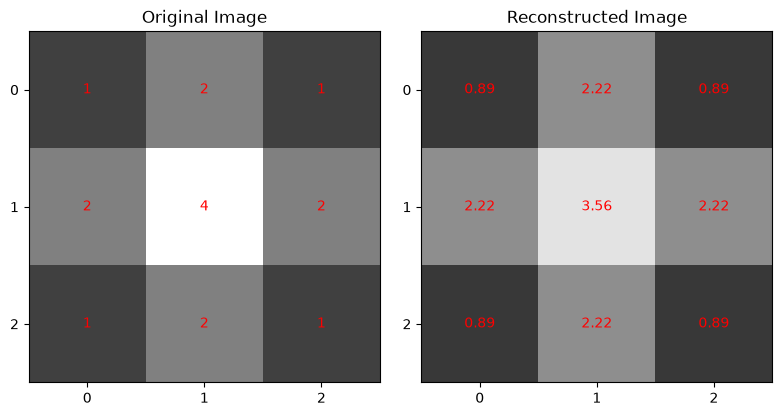

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# original 3x3 test image: a strongly attenuating centre pixel surrounded by weaker material
X_og = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])

x = X_og.flatten()  # flatten into the pixel vector (x1, ..., x9)

# 6 ray-path vectors: 3 horizontal rays (rows) followed by 3 vertical rays (columns)
A6 = np.array([[1, 1, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 1, 1, 1, 0, 0, 0], [0, 0, 0, 0, 0, 0, 1, 1, 1],
               [1, 0, 0, 1, 0, 0, 1, 0, 0], [0, 1, 0, 0, 1, 0, 0, 1, 0], [0, 0, 1, 0, 0, 1, 0, 0, 1]])

b6 = A6 @ x  # simulated noise-free measurements

x_new = np.linalg.pinv(A6) @ b6  # smallest-length image that fits all 6 measurements

X_new = x_new.reshape(3, 3)  # reshape back into a 3x3 image

rmse = np.sqrt(np.mean((x - x_new)**2))  # root-mean-square error vs. the original image

print("Original image:")
print(X_og)

print("Reconstructed image:")
print(np.round(X_new, 2))

print("Rank of measurement matrix:", np.linalg.matrix_rank(A6))
print("RMSE:", round(rmse, 4))

# check whether the reconstruction reproduces the measurements
print("Measurements b6:", b6)
print("Reconstruction fits all 6 measurements:", np.allclose(A6 @ x_new, b6))

# plot the original and reconstructed images side by side on the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

images = [X_og, X_new]
titles = ["Original Image", "Reconstructed Image"]

for i in range(2):
    axes[i].imshow(images[i], cmap="gray", vmin=0, vmax=4)
    axes[i].set_title(titles[i])
    axes[i].set_xticks([0, 1, 2])
    axes[i].set_yticks([0, 1, 2])

    # write each pixel value on top of the image
    for r in range(3):
        for c in range(3):
            axes[i].text(c, r, round(images[i][r, c], 2), ha="center", va="center", color="red")

plt.tight_layout()
plt.show()

Overall, the results of the experiment show that the reconstructed image is similar, although not exactly the same as the original. The RMSE was 0.2222, meaning that the reconstructed pixel values were off by about 0.22 on average, which is 12.5% of the average pixel value of the original image. The centre pixel dropped from 4 to 3.56 while the edge pixels rose from 2 to 2.22, so the reconstruction spreads part of the bright centre out into its row and column.

Using the six horizontal and vertical measurements, we were able to calculate a reconstruction that reproduces every measurement $\boldsymbol{b}_6 = (4, 8, 4, 4, 8, 4)^T$ exactly, even though its pixel values are not the same as the original values. This shows that different images can produce the same set of measurements, making it impossible to determine the exact original image, just as in the example from Kudo et al. (2013, Fig. 5). The rank of 5 explains why: the three row sums and the three column sums both add up to the total of all 9 pixels, so only 5 of the 6 equations are independent, leaving $9 - 5 = 4$ free variables.

In [19]:
# a diagonal ray crosses each square pixel corner to corner, so its path length is sqrt(2)
# pixel indices are row-major: x1 -> 0, x2 -> 1, ..., x9 -> 8
def diagonal_ray(pixels):
    v = np.zeros(9)
    v[pixels] = np.sqrt(2)
    return v

# 5 rays parallel to the main diagonal (x1, x5, x9) and 5 parallel to the anti-diagonal (x3, x5, x7)
A_main = np.array([diagonal_ray(p) for p in ([2], [1, 5], [0, 4, 8], [3, 7], [6])])
A_anti = np.array([diagonal_ray(p) for p in ([0], [1, 3], [2, 4, 6], [5, 7], [8])])

A16 = np.vstack([A6, A_main, A_anti])  # 4 views: rows, columns and both diagonals (16 rays)

b16 = A16 @ x  # simulated noise-free measurements

x16 = np.linalg.pinv(A16) @ b16  # reconstruct from all 16 measurements

rmse16 = np.sqrt(np.mean((x - x16)**2))  # root-mean-square error vs. the original image

print("Reconstructed image (4 views):")
print(np.round(x16.reshape(3, 3), 2))

print("Rank of measurement matrix:", np.linalg.matrix_rank(A16))
print("RMSE:", round(rmse16, 4))

Reconstructed image (4 views):
[[1. 2. 1.]
 [2. 4. 2.]
 [1. 2. 1.]]
Rank of measurement matrix: 9
RMSE: 0.0


After adding the two diagonal views, the rank increased from 5 to 9, which is the number of unknowns, so every variable has a pivot and the image is uniquely determined. The reconstruction now matches the original exactly, and the RMSE dropped from 0.2222 to 0. This makes sense because the corner pixels each have their own single-pixel diagonal ray, and once the corners are known, the row and column sums give the rest of the image.

The results show that two views are not enough to reconstruct even a $3 \times 3$ image, but adding diagonal measurements provided information from new directions that hadn't been taken into account, and four views were enough to determine the image uniquely. This agrees with Han et al. (2012), whose reconstruction error also decreased as the number of views increased. However, this conclusion is only supported for noise-free measurements of our one test image. A limitation is the fact that our measurements are exact, so once the rank reached 9, a perfect fit to the data guaranteed a perfect image. A real detector adds noise to every measurement, so it remains uncertain whether four views would still give an accurate image, or whether the same number of views would be enough for a larger image. A next step could be to add a small amount of random noise to the measurements and see how much the RMSE grows. We think that it would be interesting to see whether the diagonal measurements still keep the reconstructed image close to the original once noise is added.


**What does this mean?** We found that two views gave a rank of 5 and an RMSE of 0.2222, while four views gave a rank of 9 and an RMSE of 0, meaning that with too few views a scanner can reconstruct the wrong image even though it fits every measurement, because the missing directions leave free variables that no ray can detect.

## References

Han, X., Bian, J., Ritman, E. L., Sidky, E. Y., & Pan, X. (2012). Optimization-based reconstruction of sparse images from few-view projections. *Physics in Medicine and Biology, 57*(16), 5245–5273. PubMed Central. https://doi.org/10.1088/0031-9155/57/16/5245

Kudo, H., Suzuki, T., & Rashed, E. A. (2013). Image reconstruction for sparse-view CT and interior CT—introduction to compressed sensing and differentiated backprojection. *Quantitative Imaging in Medicine and Surgery, 3*(3), 147–161. PubMed Central. https://doi.org/10.3978/j.issn.2223-4292.2013.06.01

<div style="text-align: center;">
    <i>We completed this assignment without using generative AI.</i>
</div>